# NumCompute — Streaming Decision Tree Demo

1. **Load** a CSV with `io.py`.
2. **Split** it into chunks to simulate a stream.
3. **Train incrementally** with `.partial_fit()` on each chunk.
4. **Log and visualise** metrics over time with `visualise.py`.

`stream_data.csv` (made by `make_stream_data.py`) has 6,000 rows: four sensor features with 3% missing values and a binary label.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Run from a clone without installing the package.
sys.path.insert(0, str(Path.cwd().parent))

from numcompute import (
    DecisionTreeClassifier, Pipeline, SimpleImputer, StandardScaler,
    StreamTrainer, read_csv, read_csv_chunks,
    compare_models, plot_metric_over_time, plot_predictions_vs_ground_truth,
)

%matplotlib inline
DATA = "stream_data.csv"

## 1. Load the CSV with `io.py`

Empty fields become NaN. The header row is skipped.

In [2]:
data = read_csv(DATA, skip_header=1)
print("shape:", data.shape)
print("missing values per feature:", np.isnan(data[:, :4]).sum(axis=0))

shape: (6000, 5)
missing values per feature: [201 184 179 154]


## 2. Split into chunks

`read_csv_chunks` reads the file 200 rows at a time.

In [3]:
CHUNK_SIZE = 200

def stream():
    for chunk in read_csv_chunks(DATA, chunk_size=CHUNK_SIZE, skip_header=1):
        yield chunk[:, :4], chunk[:, 4].astype(int)

chunks = list(stream())
print(len(chunks), "chunks of", CHUNK_SIZE, "rows")

30 chunks of 200 rows


## 3. Train incrementally with `partial_fit`

Pipeline: imputer → scaler → `DecisionTreeClassifier(max_depth=6, buffer_size=600)`. Each `partial_fit` adds the chunk to the tree's buffer; when 600 samples are buffered the tree is retrained and the buffer is cleared.

`StreamTrainer` scores each chunk **before** training on it, so every score is on unseen data.

In [4]:
def make_pipeline(buffer_size):
    return Pipeline([
        ("impute", SimpleImputer("median")),
        ("scale", StandardScaler()),
        ("tree", DecisionTreeClassifier(max_depth=6, buffer_size=buffer_size,
                                        random_state=0)),
    ])

pipe = make_pipeline(buffer_size=600)
trainer = StreamTrainer(pipe)

for i, (X_chunk, y_chunk) in enumerate(chunks):
    if i == len(chunks) - 1:
        last_pred = pipe.predict(X_chunk)     # latest chunk, before training on it
    trainer.process_chunk(X_chunk, y_chunk)   # score, then pipe.partial_fit

print(f"{'chunk':>5} {'accuracy':>9} {'cumulative':>11} {'retrained':>10} {'memory KB':>10}")
for e in trainer.history_[:8]:
    print(f"{e['chunk']:>5} {e['chunk_accuracy']:>9.3f} {e['cumulative_accuracy']:>11.3f} "
          f"{str(e['retrained']):>10} {e['memory_bytes'] / 1024:>10.1f}")
trainer.summary()

chunk  accuracy  cumulative  retrained  memory KB
    0       nan         nan      False       19.7
    1       nan         nan      False       39.0
    2       nan         nan       True       40.5
    3     0.905       0.905      False       59.9
    4     0.845       0.875      False       79.2
    5     0.890       0.880       True       35.7
    6     0.855       0.874      False       55.1
    7     0.915       0.882      False       74.3


{'n_chunks': 30,
 'n_samples': 6000,
 'cumulative_accuracy': 0.8785185185185185,
 'total_fit_time': 0.17391699999999854,
 'n_retrains': 10,
 'final_memory_bytes': 36520}

The first chunks show `nan` because no tree exists until 600 samples are buffered.

## 4. Visualise

### Accuracy and error over time

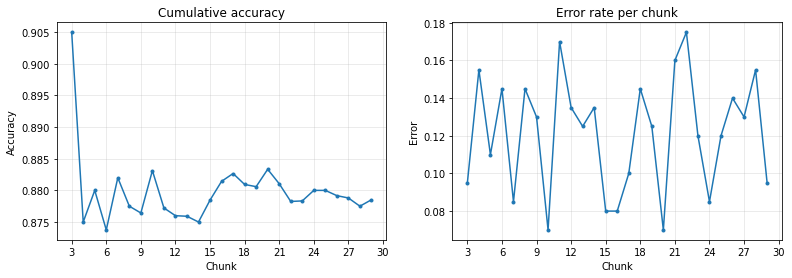

In [5]:
fig, (ax_acc, ax_err) = plt.subplots(1, 2, figsize=(13, 4))
plot_metric_over_time(trainer.get_metric("cumulative_accuracy"),
                      title="Cumulative accuracy", ylabel="Accuracy", ax=ax_acc)
plot_metric_over_time(1 - trainer.get_metric("chunk_accuracy"),
                      title="Error rate per chunk", ylabel="Error", ax=ax_err)
plt.show()

### Model comparison: two buffer sizes

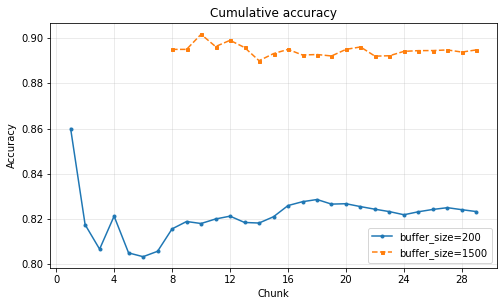

In [6]:
small = StreamTrainer(make_pipeline(buffer_size=200)).run(stream())
large = StreamTrainer(make_pipeline(buffer_size=1500)).run(stream())

compare_models(small.get_metric("cumulative_accuracy"),
               large.get_metric("cumulative_accuracy"),
               labels=("buffer_size=200", "buffer_size=1500"),
               title="Cumulative accuracy", ylabel="Accuracy")
plt.show()

### Predictions vs ground truth on the latest chunk

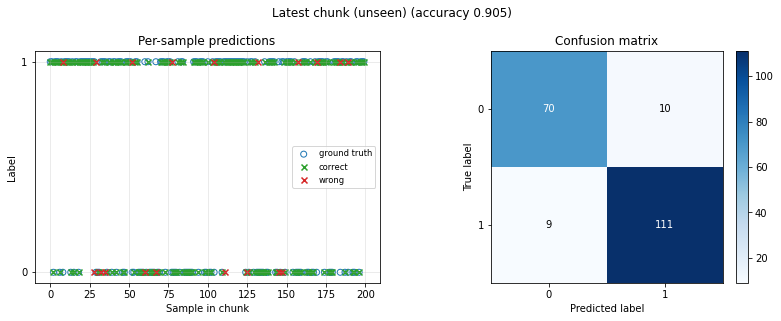

In [7]:
plot_predictions_vs_ground_truth(chunks[-1][1], last_pred,
                                 title="Latest chunk (unseen)")
plt.show()

Benchmarks (loop vs vectorised, and the effect of `buffer_size`) are run with `python -m numcompute.benchmarking`; results are in the README.